## Cell 1 — Set up the analysis environment
This cell imports the libraries used throughout the exploratory analysis, including pandas and NumPy for data handling and Matplotlib/Seaborn for visualization. Keeping the analysis environment defined at the beginning makes the notebook reproducible.

In [54]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries loaded successfully!")

Libraries loaded successfully!


## Cell 2 — Define the dataset location
This cell defines the common dataset directory so that the JSON files can be loaded consistently without repeating the full path in every cell.

In [55]:
DATA_FOLDER = "../data/RokomariBG_Dataset"

print(DATA_FOLDER)

../data/RokomariBG_Dataset


## Cell 3 — Load the main book dataset
This cell loads the main book-level dataset and confirms that the expected records are available. The book table is the primary source for title, summary, author, publisher, and other metadata.

In [56]:
books = pd.read_json(f"{DATA_FOLDER}/book.json")

print("Books loaded successfully!")
print("Number of books:", len(books))

Books loaded successfully!
Number of books: 149515


## Cell 4 — Preview the first book records
Preview the first book records. This cell performs the `preview the first book records` step as part of the analysis pipeline. The result is used to verify the data, support a modeling decision, or prepare the next stage of the workflow.

In [57]:
books.head()

,book_id,book_title,category_id,book_summary,book_price,price_currency,offer_price,stock_message,stock_quantity,isbn,book_pages,book_availability,author_id,publisher_id,average_rating,rating_count,review_count,wished_customer_count,best_seller_badge,book_url
0,1,সুশাসনের সন্ধানে,1392,"""সুশাসনের সন্ধানে"" বইটির প্রথম ফ্ল্যাপ-এর লেখা...",325.0,BDT,280.0,NaN,NaN,9848682368,216.0,InStock,273,1.0,5.00,5.0,2.0,NaN,NaN,https://www.rokomari.com/book/1/sushasoner-son...
1,2,শেষেরকবিতা,678,‘শেষের কবিতা’ বইয়ের কিছু অংশঃ অমিত-চরিত অমিত র...,250.0,BDT,215.0,NaN,NaN,98483091351,78.0,InStock,930,42.0,4.24,84.0,46.0,651.0,NaN,https://www.rokomari.com/book/2/sheser-kobita
2,2,শেষেরকবিতা,678,‘শেষের কবিতা’ বইয়ের কিছু অংশঃ অমিত-চরিত অমিত র...,250.0,BDT,215.0,NaN,NaN,98483091351,78.0,InStock,930,42.0,4.24,84.0,46.0,651.0,NaN,https://www.rokomari.com/book/2/sheser-kobita
3,3,নৌকাডুবি,678,"""নৌকাডুবি” বইয়ের ভূমিকার থেকে নেয়া: পাঠক যে ভা...",320.0,BDT,275.0,In Stock (only 1 copy left),NaN,98483091431,156.0,InStock,930,42.0,4.40,20.0,10.0,161.0,NaN,https://www.rokomari.com/book/3/noukadubi
4,3,নৌকাডুবি,678,"""নৌকাডুবি” বইয়ের ভূমিকার থেকে নেয়া: পাঠক যে ভা...",320.0,BDT,275.0,In Stock (only 1 copy left),NaN,98483091431,156.0,InStock,930,42.0,4.40,20.0,10.0,161.0,NaN,https://www.rokomari.com/book/3/noukadubi


## Cell 5 — Check the dataset dimensions
This check establishes the number of records and variables in the raw book dataset and provides the starting point for the subsequent data-quality analysis.

In [58]:
books.shape

(149515, 20)

## Cell 6 — Inspect the available variables
Inspect the available variables. This cell performs the `inspect the available variables` step as part of the analysis pipeline. The result is used to verify the data, support a modeling decision, or prepare the next stage of the workflow.

In [59]:
books.columns

Index(['book_id', 'book_title', 'category_id', 'book_summary', 'book_price',
       'price_currency', 'offer_price', 'stock_message', 'stock_quantity',
       'isbn', 'book_pages', 'book_availability', 'author_id', 'publisher_id',
       'average_rating', 'rating_count', 'review_count',
       'wished_customer_count', 'best_seller_badge', 'book_url'],
      dtype='str')

## Cell 7 — Inspect data types and non-null counts
Inspect data types and non-null counts. This cell performs the `inspect data types and non-null` counts step as part of the analysis pipeline. The result is used to verify the data, support a modeling decision, or prepare the next stage of the workflow.

In [60]:
books.info()

<class 'pandas.DataFrame'>
RangeIndex: 149515 entries, 0 to 149514
Data columns (total 20 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   book_id                149515 non-null  int64  
 1   book_title             149515 non-null  str    
 2   category_id            149515 non-null  int64  
 3   book_summary           149175 non-null  str    
 4   book_price             149175 non-null  float64
 5   price_currency         149515 non-null  str    
 6   offer_price            102860 non-null  float64
 7   stock_message          34939 non-null   str    
 8   stock_quantity         17168 non-null   float64
 9   isbn                   94473 non-null   str    
 10  book_pages             120669 non-null  float64
 11  book_availability      149515 non-null  str    
 12  author_id              149515 non-null  int64  
 13  publisher_id           149175 non-null  float64
 14  average_rating         149163 non-null  float64

## Cell 8 — Review descriptive statistics
eview descriptive statistics. This cell performs the `review descriptive statistics` step as part of the analysis pipeline. The result is used to verify the data, support a modeling decision, or prepare the next stage of the workflow.

In [61]:
books.describe()

,book_id,category_id,book_price,offer_price,stock_quantity,book_pages,author_id,publisher_id,average_rating,rating_count,review_count,wished_customer_count
count,149515.000000,149515.000000,149175.000000,102860.000000,17168.000000,120669.000000,149515.000000,149175.000000,149163.000000,149171.000000,149175.000000,6632.000000
mean,211709.233254,1395.726435,1206.810504,294.214505,5.779823,288.660145,39210.445300,3557.518874,4.791351,3.745809,2.034758,239.309107
std,142223.293552,1587.607671,3748.541567,592.240115,7.074180,412.004604,37274.442343,4286.324289,0.596715,36.627041,22.077310,182.433822
min,1.000000,1.000000,0.000000,0.000000,2.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,1.000000
25%,91633.000000,553.000000,186.000000,126.000000,2.000000,100.000000,7649.000000,371.000000,5.000000,0.000000,0.000000,124.000000
50%,189471.000000,911.000000,320.000000,206.000000,3.000000,192.000000,25439.000000,1261.000000,5.000000,0.000000,0.000000,176.000000
75%,321816.500000,1541.000000,680.000000,333.000000,6.000000,360.000000,69623.500000,5351.000000,5.000000,2.000000,1.000000,294.000000
max,512230.000000,8306.000000,101914.000000,65060.000000,50.000000,41698.000000,134503.000000,18971.000000,22.000000,3997.000000,2158.000000,998.000000


## Cell 9 — Measure missing values
This analysis counts missing values in every variable so we can identify which fields are complete enough for modeling and which require special handling.

In [62]:
missing_values = books.isnull().sum()

missing_values

book_id                       0
book_title                    0
category_id                   0
book_summary                340
book_price                  340
price_currency                0
offer_price               46655
stock_message            114576
stock_quantity           132347
isbn                      55042
book_pages                28846
book_availability             0
author_id                     0
publisher_id                340
average_rating              352
rating_count                344
review_count                340
wished_customer_count    142883
best_seller_badge        139720
book_url                      0
dtype: int64

## Cell 10 — Measure the percentage of missing values
Percentages make missingness comparable across variables and help distinguish fields that are broadly complete from those with substantial missing information.

In [63]:
missing_percentage = (books.isnull().sum() / len(books)) * 100

missing_percentage.sort_values(ascending=False)

wished_customer_count    95.564325
best_seller_badge        93.448818
stock_quantity           88.517540
stock_message            76.631776
isbn                     36.813698
offer_price              31.204227
book_pages               19.293048
average_rating            0.235428
rating_count              0.230077
review_count              0.227402
book_price                0.227402
book_summary              0.227402
publisher_id              0.227402
category_id               0.000000
book_id                   0.000000
book_title                0.000000
book_availability         0.000000
price_currency            0.000000
author_id                 0.000000
book_url                  0.000000
dtype: float64

## Cell 11 — Check for exact duplicate rows
Exact duplicate rows are checked before modeling so that repeated records are not mistaken for additional independent observations.

In [64]:
books.duplicated().sum()

np.int64(18975)

## Cell 12 — Check for duplicated book IDs
Repeated book IDs can represent duplicated records, so this check helps determine whether the raw book table contains multiple rows for the same book identifier.

In [65]:
books["book_id"].duplicated().sum()

np.int64(22213)

## Cell 13 — Check basic title and summary completeness
This check establishes whether the two main textual inputs are present before deeper text analysis begins.

In [66]:
print("Empty titles:", (books["book_title"].str.strip() == "").sum())
print("Empty summaries:", (books["book_summary"].fillna("").str.strip() == "").sum())

Empty titles: 0
Empty summaries: 340


## Cell 14 — Inspect repeated book IDs
This inspection provides concrete examples of repeated book IDs and helps determine whether the repetitions are identical records or potentially different records.

In [67]:
duplicate_book_ids = books[
    books["book_id"].duplicated(keep=False)
].sort_values("book_id")

duplicate_book_ids.head(20)

,book_id,book_title,category_id,book_summary,book_price,price_currency,offer_price,stock_message,stock_quantity,isbn,book_pages,book_availability,author_id,publisher_id,average_rating,rating_count,review_count,wished_customer_count,best_seller_badge,book_url
1,2,শেষেরকবিতা,678,‘শেষের কবিতা’ বইয়ের কিছু অংশঃ অমিত-চরিত অমিত র...,250.0,BDT,215.0,NaN,NaN,98483091351,78.0,InStock,930,42.0,4.24,84.0,46.0,651.0,NaN,https://www.rokomari.com/book/2/sheser-kobita
2,2,শেষেরকবিতা,678,‘শেষের কবিতা’ বইয়ের কিছু অংশঃ অমিত-চরিত অমিত র...,250.0,BDT,215.0,NaN,NaN,98483091351,78.0,InStock,930,42.0,4.24,84.0,46.0,651.0,NaN,https://www.rokomari.com/book/2/sheser-kobita
3,3,নৌকাডুবি,678,"""নৌকাডুবি” বইয়ের ভূমিকার থেকে নেয়া: পাঠক যে ভা...",320.0,BDT,275.0,In Stock (only 1 copy left),NaN,98483091431,156.0,InStock,930,42.0,4.40,20.0,10.0,161.0,NaN,https://www.rokomari.com/book/3/noukadubi
4,3,নৌকাডুবি,678,"""নৌকাডুবি” বইয়ের ভূমিকার থেকে নেয়া: পাঠক যে ভা...",320.0,BDT,275.0,In Stock (only 1 copy left),NaN,98483091431,156.0,InStock,930,42.0,4.40,20.0,10.0,161.0,NaN,https://www.rokomari.com/book/3/noukadubi
5,4,গোরা,678,Show More,300.0,BDT,259.0,NaN,NaN,NaN,239.0,InStock,930,42.0,4.75,8.0,3.0,NaN,NaN,https://www.rokomari.com/book/4/gora
6,4,গোরা,678,Show More,300.0,BDT,259.0,NaN,NaN,NaN,239.0,InStock,930,42.0,4.75,8.0,3.0,NaN,NaN,https://www.rokomari.com/book/4/gora
7,5,চোখের বালি,678,”চোখের বালি” বইটির সম্পর্কে কিছু কথাঃ চোখের বা...,300.0,BDT,259.0,NaN,NaN,98483095246,156.0,InStock,930,42.0,4.93,14.0,8.0,NaN,NaN,https://www.rokomari.com/book/5/chokher-bali
8,5,চোখের বালি,678,”চোখের বালি” বইটির সম্পর্কে কিছু কথাঃ চোখের বা...,300.0,BDT,259.0,In Stock (only 2 copies left),2.0,98483095246,156.0,InStock,930,42.0,4.93,14.0,8.0,NaN,NaN,https://www.rokomari.com/book/5/chokher-bali
9,6,ঘরে,678,Show More,300.0,BDT,259.0,NaN,NaN,NaN,128.0,InStock,930,42.0,4.20,5.0,1.0,NaN,NaN,https://www.rokomari.com/book/6/ghore-baire
10,6,ঘরে,678,Show More,300.0,BDT,259.0,NaN,NaN,NaN,128.0,InStock,930,42.0,4.20,5.0,1.0,NaN,NaN,https://www.rokomari.com/book/6/ghore-baire


## Cell 15 — Quantify unique and duplicated book IDs
This cell quantifies the number of unique book identifiers and duplicate occurrences, providing a clearer picture of the raw table's record structure.

In [68]:
unique_book_ids = books["book_id"].nunique()

print("Total rows:", len(books))
print("Unique book IDs:", unique_book_ids)
print("Duplicate ID occurrences:", len(books) - unique_book_ids)

Total rows: 149515
Unique book IDs: 127302
Duplicate ID occurrences: 22213


## Cell 16 — Summarize how often book IDs are repeated
Summarize how often book IDs are repeated. This cell performs the `summarize how often book ids are repeated` step as part of the analysis pipeline. The result is used to verify the data, support a modeling decision, or prepare the next stage of the workflow.

In [69]:
duplicate_id_summary = (
    books.groupby("book_id")
    .agg(
        occurrences=("book_id", "size"),
        unique_titles=("book_title", "nunique")
    )
)

duplicate_id_summary[
    duplicate_id_summary["occurrences"] > 1
].sort_values("occurrences", ascending=False).head(20)

,occurrences,unique_titles
book_id,,
190689,5,1
201713,5,1
201854,5,1
191744,5,1
201590,5,1
209429,4,1
194299,4,1
433264,4,1
190688,4,1


## Cell 17 — Inspect one repeated book ID in detail
Inspect one repeated book ID in detail. This cell performs the `inspect one repeated book id in detail` step as part of the analysis pipeline. The result is used to verify the data, support a modeling decision, or prepare the next stage of the workflow.

In [70]:
books[books["book_id"] == 190689]

,book_id,book_title,category_id,book_summary,book_price,price_currency,offer_price,stock_message,stock_quantity,isbn,book_pages,book_availability,author_id,publisher_id,average_rating,rating_count,review_count,wished_customer_count,best_seller_badge,book_url
75304,190689,যেভাবে স্বামীর হৃদয় জয় করবেন,2737,বইটি যে জন্য লেখা- ১. অধিকহারে বিবাহ সংক্রান্ত...,160.0,BDT,80.0,In Stock (50+ copies available),NaN,NaN,64.0,InStock,74729,8297.0,4.46,28.0,12.0,389.0,#6 Best Seller in,https://www.rokomari.com/book/190689/jebave-sh...
75305,190689,যেভাবে স্বামীর হৃদয় জয় করবেন,2737,বইটি যে জন্য লেখা- ১. অধিকহারে বিবাহ সংক্রান্ত...,160.0,BDT,80.0,In Stock (50+ copies available),NaN,NaN,64.0,InStock,74729,8297.0,4.46,28.0,12.0,389.0,#6 Best Seller in,https://www.rokomari.com/book/190689/jebave-sh...
75306,190689,যেভাবে স্বামীর হৃদয় জয় করবেন,2737,বইটি যে জন্য লেখা- ১. অধিকহারে বিবাহ সংক্রান্ত...,160.0,BDT,77.0,In Stock (only 18 copies left),18.0,NaN,64.0,InStock,74729,8297.0,4.48,27.0,12.0,384.0,#6 Best Seller in,https://www.rokomari.com/book/190689/jebave-sh...
75307,190689,যেভাবে স্বামীর হৃদয় জয় করবেন,2737,বইটি যে জন্য লেখা- ১. অধিকহারে বিবাহ সংক্রান্ত...,160.0,BDT,77.0,In Stock (only 18 copies left),18.0,NaN,64.0,InStock,74729,8297.0,4.48,27.0,12.0,384.0,#6 Best Seller in,https://www.rokomari.com/book/190689/jebave-sh...
75308,190689,যেভাবে স্বামীর হৃদয় জয় করবেন,2737,বইটি যে জন্য লেখা- ১. অধিকহারে বিবাহ সংক্রান্ত...,160.0,BDT,80.0,In Stock (50+ copies available),NaN,NaN,64.0,InStock,74729,8297.0,4.46,28.0,12.0,389.0,#6 Best Seller in,https://www.rokomari.com/book/190689/jebave-sh...


## Cell 18 — Quantify records associated with repeated IDs
Quantify records associated with repeated IDs. This cell performs the `quantify records associated with repeated ids` step as part of the analysis pipeline. The result is used to verify the data, support a modeling decision, or prepare the next stage of the workflow.

In [71]:
repeated_ids = books.loc[
    books["book_id"].duplicated(keep=False),
    "book_id"
].unique()

repeated_data = books[
    books["book_id"].isin(repeated_ids)
]

different_records = (
    repeated_data.groupby("book_id")
    .size()
)

print("Number of repeated book IDs:", len(repeated_ids))
print("Number of rows belonging to repeated IDs:", len(repeated_data))

Number of repeated book IDs: 22118
Number of rows belonging to repeated IDs: 44331


## Cell 19 — Check whether repeated IDs have varying metadata
Repeated IDs are compared across key fields to see whether the duplicate rows actually contain different information that might need special treatment.

In [72]:
columns_to_check = [
    "book_title",
    "category_id",
    "book_summary",
    "book_price",
    "offer_price",
    "author_id",
    "publisher_id",
    "average_rating",
    "rating_count",
    "review_count"
]

different_id_records = (
    repeated_data
    .groupby("book_id")[columns_to_check]
    .nunique()
)

different_id_records.head()

,book_title,category_id,book_summary,book_price,offer_price,author_id,publisher_id,average_rating,rating_count,review_count
book_id,,,,,,,,,,
2,1,1,1,1,1,1,1,1,1,1
3,1,1,1,1,1,1,1,1,1,1
4,1,1,1,1,1,1,1,1,1,1
5,1,1,1,1,1,1,1,1,1,1
6,1,1,1,1,1,1,1,1,1,1


## Cell 20 — Summarize which fields vary across repeated IDs
Summarize which fields vary across repeated IDs. This cell performs the `summarize which fields vary across repeated ids` step as part of the analysis pipeline. The result is used to verify the data, support a modeling decision, or prepare the next stage of the workflow.

In [73]:
varying_columns = (
    different_id_records
    .max()
    .sort_values(ascending=False)
)

varying_columns

book_title        2
category_id       2
book_summary      2
book_price        2
offer_price       2
author_id         2
average_rating    2
rating_count      2
review_count      2
publisher_id      1
dtype: int64

## Cell 21 — Count variation across repeated-book fields
Count variation across repeated-book fields. This cell performs the `count variation across repeated-book fields` step as part of the analysis pipeline. The result is used to verify the data, support a modeling decision, or prepare the next stage of the workflow.

In [74]:
variation_mask = different_id_records > 1

variation_counts = variation_mask.sum().sort_values(ascending=False)

variation_counts

offer_price       382
review_count      102
rating_count       81
average_rating     55
book_price         13
book_summary        6
category_id         5
author_id           3
book_title          2
publisher_id        0
dtype: int64

## Cell 22 — Identify repeated IDs with different category assignments
Identify repeated IDs with different category assignments. This cell performs the `identify repeated ids with different category assignments` step as part of the analysis pipeline. The result is used to verify the data, support a modeling decision, or prepare the next stage of the workflow.

In [75]:
category_variation = different_id_records[
    different_id_records["category_id"] > 1
]

category_variation[["category_id"]]

,category_id
book_id,
129826,2
198585,2
206872,2
446016,2
511362,2


## Cell 23 — List book IDs with category variation
List book IDs with category variation. This cell performs the `list book ids with category variation` step as part of the analysis pipeline. The result is used to verify the data, support a modeling decision, or prepare the next stage of the workflow.

In [76]:
category_variation.index.tolist()

[129826, 198585, 206872, 446016, 511362]

## Cell 24 — Identify repeated IDs with different titles
Identify repeated IDs with different titles. This cell performs the `identify repeated ids with different titles` step as part of the analysis pipeline. The result is used to verify the data, support a modeling decision, or prepare the next stage of the workflow.

In [77]:
title_variation = different_id_records[
    different_id_records["book_title"] > 1
]

title_variation[["book_title"]]

,book_title
book_id,
206872,2
446016,2


## Cell 25 — Load the category reference table
Load the category reference table. This cell performs the `load the category reference table` step as part of the analysis pipeline. The result is used to verify the data, support a modeling decision, or prepare the next stage of the workflow.

In [78]:
categories = pd.read_json(f"{DATA_FOLDER}/category.json")

print("Categories loaded successfully!")
print("Number of categories:", len(categories))

Categories loaded successfully!
Number of categories: 1516


## Cell 26 — Preview category records
Preview category records. This cell performs the `preview category records` step as part of the analysis pipeline. The result is used to verify the data, support a modeling decision, or prepare the next stage of the workflow.

In [79]:
categories.head()

,category_id,category_name,category_description,books_count
0,1,Book,"দেশি বিদেশি সকল ধর্মীয়, ফিকশন, নন ফিকশন, স্কিল...",1637.0
1,10,"Business, Investing & Economics","ব্যবসা, বিনিয়োগ ও অর্থনীতি সংক্রান্ত সকল অরিজি...",1802.0
2,1000,Department of Psychology,মনোবিজ্ঞান বিষয়ক সকল অরিজিনাল বই সংগ্রহ করুন র...,60.0
3,1001,Department of Microbiology,অনুজীববিজ্ঞান বিভাগ বিষয়ক সকল অরিজিনাল বই সংগ্...,60.0
4,1002,Department of Pharmacy,ফার্মেসি বিভাগ বিষয়ক সকল অরিজিনাল বই সংগ্রহ কর...,19.0


## Cell 27 — Inspect category metadata structure
Inspect category metadata structure. This cell performs the `inspect category metadata structure` step as part of the analysis pipeline. The result is used to verify the data, support a modeling decision, or prepare the next stage of the workflow.

In [80]:
categories.info()

<class 'pandas.DataFrame'>
RangeIndex: 1516 entries, 0 to 1515
Data columns (total 4 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   category_id           1516 non-null   int64  
 1   category_name         1516 non-null   str    
 2   category_description  1516 non-null   str    
 3   books_count           1493 non-null   float64
dtypes: float64(1), int64(1), str(2)
memory usage: 47.5 KB


## Cell 28 — Load the book-category relationship table
Load the book-category relationship table. This cell performs the `load the book-category relationship table` step as part of the analysis pipeline. The result is used to verify the data, support a modeling decision, or prepare the next stage of the workflow.

In [81]:
book_categories = pd.read_json(
    f"{DATA_FOLDER}/book_to_category.json"
)

print("Book-category relationships loaded successfully!")
print("Number of relationships:", len(book_categories))

Book-category relationships loaded successfully!
Number of relationships: 235475


## Cell 29 — Preview book-category relationships
Preview book-category relationships. This cell performs the `preview book-category relationships` step as part of the analysis pipeline. The result is used to verify the data, support a modeling decision, or prepare the next stage of the workflow.

In [82]:
book_categories.head()

,book_id,category_id
0,1,1392
1,1,904
2,10,688
3,100,18
4,100,623


## Cell 30 — Inspect relationship-table structure
Inspect relationship-table structure. This cell performs the `inspect relationship-table structure` step as part of the analysis pipeline. The result is used to verify the data, support a modeling decision, or prepare the next stage of the workflow.

In [83]:
book_categories.info()

<class 'pandas.DataFrame'>
RangeIndex: 235475 entries, 0 to 235474
Data columns (total 2 columns):
 #   Column       Non-Null Count   Dtype
---  ------       --------------   -----
 0   book_id      235475 non-null  int64
 1   category_id  235475 non-null  int64
dtypes: int64(2)
memory usage: 3.6 MB


## Cell 31 — Count books with at least one category
This establishes how many unique books have at least one category assignment and therefore can participate in the supervised classification task.

In [84]:
unique_books_with_categories = book_categories["book_id"].nunique()

print("Unique books with at least one category:",
        unique_books_with_categories)

Unique books with at least one category: 107680


## Cell 32 — Count categories actually used
This identifies how many category labels are actually represented in the relationship data rather than relying only on the size of the category reference table.

In [85]:
unique_categories_used = book_categories["category_id"].nunique()

print("Unique categories used:", unique_categories_used)

Unique categories used: 1493


## Cell 33 — Check for duplicate book-category relationships
Duplicate relationships are checked to ensure that the same book-category assignment has not been recorded multiple times.

In [86]:
duplicate_relationships = book_categories.duplicated().sum()

print("Duplicated book-category relationships:",
        duplicate_relationships)

Duplicated book-category relationships: 0


## Cell 34 — Measure the number of categories assigned to each book
The number of labels per book is calculated to determine whether the problem is naturally single-label or multi-label.

In [87]:
categories_per_book = (
    book_categories
    .groupby("book_id")["category_id"]
    .nunique()
)

categories_per_book.describe()

count    107680.000000
mean          2.186803
std           1.608305
min           1.000000
25%           1.000000
50%           2.000000
75%           3.000000
max          30.000000
Name: category_id, dtype: float64

## Cell 35 — Summarize the distribution of category counts per book
Summarize the distribution of category counts per book. This cell performs the `summarize the distribution of category counts per book` step as part of the analysis pipeline. The result is used to verify the data, support a modeling decision, or prepare the next stage of the workflow.

In [88]:
category_count_destribution = (
    categories_per_book
    .value_counts()
    .sort_index()
)

category_count_destribution

category_id
1     45560
2     31171
3     15440
4      7543
5      3548
6      1904
7      1011
8       582
9       348
10      195
11      124
12       60
13       39
14       46
15       35
16       19
17       14
18       16
19       11
20        8
21        1
22        2
23        1
25        1
30        1
Name: count, dtype: int64

## Cell 36 — Plot the distribution of categories per book
Plot the distribution of categories per book. This cell performs the `plot the distribution of categories per book` step as part of the analysis pipeline. The result is used to verify the data, support a modeling decision, or prepare the next stage of the workflow.

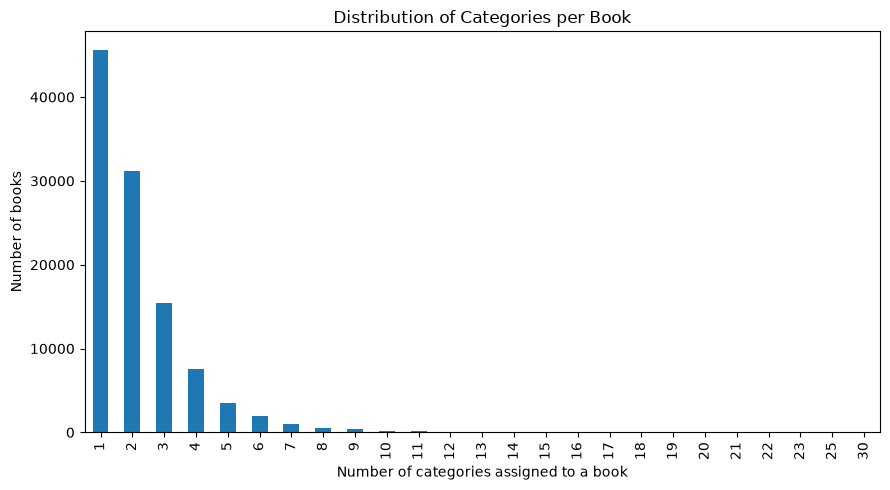

In [89]:
plt.figure(figsize=(9, 5))

category_count_destribution.plot(
    kind="bar"
)

plt.xlabel("Number of categories assigned to a book")
plt.ylabel("Number of books")
plt.title("Distribution of Categories per Book")

plt.tight_layout()

plt.savefig(
    "../results/figures/figure2_categories_per_book.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Interpret the category-count distribution
The distribution is right-skewed, with most books having relatively few labels and a smaller number having many labels.

## Cell 37 — Quantify single-label and multi-label books
This separates books with one label from books with multiple labels and quantifies the prevalence of the multi-label structure.

In [90]:
multi_label_books = (categories_per_book > 1).sum()
single_label_books = (categories_per_book == 1).sum()

print("Books with one category:", single_label_books)
print("Books with multiple category:", multi_label_books)
print(
    "Percentage with multi label:",
    round(multi_label_books / len(categories_per_book) * 100, 2), 
    "%"
)

Books with one category: 45560
Books with multiple category: 62120
Percentage with multi label: 57.69 %


## Cell 38 — Inspect the most frequent categories
The most frequently assigned categories are inspected to understand which labels dominate the dataset.

In [91]:
category_frequency = (
    book_categories
    .groupby("category_id")["book_id"]
    .nunique()
    .sort_values(ascending=False)
)

category_frequency.head(20)

category_id
32      1826
1       1608
31      1602
30      1549
81      1526
403     1490
35      1455
371     1431
407     1409
10      1400
9       1283
363     1261
90      1250
2389    1226
19      1216
40      1192
14      1180
1983    1170
91      1162
364     1120
Name: book_id, dtype: int64

## Cell 39 — Summarize category-frequency statistics
These statistics summarize the center, spread, minimum, and maximum category sizes and provide the basis for the rare-category analysis.

In [92]:
category_frequency.describe()

count    1493.000000
mean      157.719357
std       251.067951
min         1.000000
25%        24.000000
50%        58.000000
75%       178.000000
max      1826.000000
Name: book_id, dtype: float64

## Cell 40 — Inspect the least frequent categories
The least frequent categories are inspected to understand the long tail and identify categories with too few examples for reliable learning.

In [93]:
category_frequency.sort_values().head(20)

category_id
8288    1
1482    1
2807    1
6623    1
6607    1
2213    1
2212    1
2768    1
4157    1
3469    1
4057    1
1873    1
4147    2
4148    2
6903    2
512     2
3467    2
4106    2
6716    2
7410    2
Name: book_id, dtype: int64

## Cell 41 — Attach category names for interpretation
Attach category names for interpretation. This cell performs the `attach category names for interpretation` step as part of the analysis pipeline. The result is used to verify the data, support a modeling decision, or prepare the next stage of the workflow.

In [94]:
category_frequency_named = (
    category_frequency
    .reset_index(name="book_count")
    .merge(
        categories[["category_id", "category_name"]],
        on = "category_id", 
        how = "left"
    )
    .sort_values("book_count", ascending=False)
)

category_frequency_named.head(20)

,category_id,book_count,category_name
0,32,1826,"Self-Help, Motivational and Meditation"
1,1,1608,Book
2,31,1602,"Mathematics, Science & Technology"
3,30,1549,Religious Books
4,81,1526,Islamic Books
5,403,1490,Foreign Language Books
6,35,1455,Translated Books
7,371,1431,Sirate Rasul S.A.W
8,407,1409,"Rhymes, Poems and Recitation"
9,10,1400,"Business, Investing & Economics"


## Cell 42 — Investigate rare categories
**Investigate rare categories.** This cell performs the `investigate rare categories` step as part of the analysis pipeline. The result is used to verify the data, support a modeling decision, or prepare the next stage of the workflow.

In [95]:
print("Categories with fewer than five books:",
        (category_frequency < 5).sum())

print("Categories with fewer than ten books:",
        (category_frequency < 10).sum())

print("Categories with fewer than twenty books:",
        (category_frequency < 20).sum())

Categories with fewer than five books: 62
Categories with fewer than ten books: 158
Categories with fewer than twenty books: 312


## Cell 43 — Plot the category-frequency distribution
The category-frequency histogram visualizes the strong right skew and long-tail behavior of the category distribution.

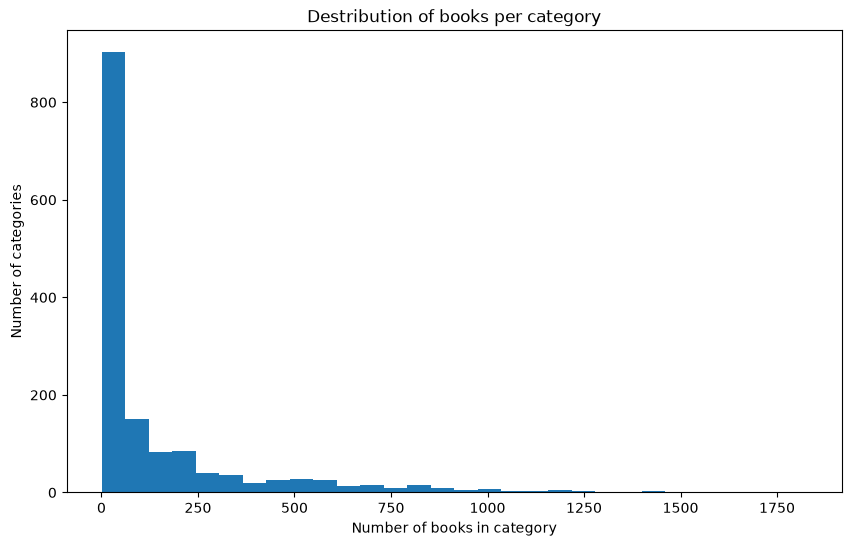

In [96]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.hist(category_frequency, bins=30)

plt.xlabel("Number of books in category")
plt.ylabel("Number of categories")
plt.title("Destribution of books per category")

plt.show()

## Cell 44 — Measure cumulative category coverage
Cumulative coverage is calculated to show how much of all category assignments is captured by the most frequent categories.

In [97]:
coverage = category_frequency.sort_values(ascending=False).reset_index()
coverage.columns = ["category_id", "book_count"]

coverage["comulative_books"] = coverage["book_count"].cumsum()

total_category_assigmnets = coverage["book_count"].sum()

coverage["coverage_percent"] = (
    coverage["comulative_books"] /
    total_category_assigmnets * 100
)

coverage.head(20)

,category_id,book_count,comulative_books,coverage_percent
0,32,1826,1826,0.775454
1,1,1608,3434,1.458329
2,31,1602,5036,2.138656
3,30,1549,6585,2.796475
4,81,1526,8111,3.444527
5,403,1490,9601,4.077291
6,35,1455,11056,4.695191
7,371,1431,12487,5.302898
8,407,1409,13896,5.901263
9,10,1400,15296,6.495806


## Cell 45 — Compare coverage achieved by different numbers of categories 
**Compare coverage achieved by different numbers of categories**. This cell performs the `compare coverage achieved by different numbers of categories` step as part of the analysis pipeline. The result is used to verify the data, support a modeling decision, or prepare the next stage of the workflow.

In [98]:
selected_points = [10, 20, 50, 100, 200, 300, 500, 750, 1000]

for n in selected_points:
    if n <= len(coverage):
        percent = coverage.iloc[n - 1]["coverage_percent"]
        print(f"Top {n:4} categories -> {percent:.2f}% of category assignments")

Top   10 categories -> 6.50% of category assignments
Top   20 categories -> 11.62% of category assignments
Top   50 categories -> 23.73% of category assignments
Top  100 categories -> 39.09% of category assignments
Top  200 categories -> 59.91% of category assignments
Top  300 categories -> 71.83% of category assignments
Top  500 categories -> 84.84% of category assignments
Top  750 categories -> 91.74% of category assignments
Top 1000 categories -> 96.67% of category assignments


## Cell 46 — Evaluate minimum-frequency thresholds
Different minimum-book thresholds are evaluated to understand how many categories would remain under each possible modeling rule.

In [99]:
thresholds = [5, 10, 20, 50, 100, 200]

for threshold in thresholds:
    selected = category_frequency[category_frequency >= threshold]

    print(
        f"Minimum {threshold:3} books -> "
        f"{len(selected):3} categories"
    )

Minimum   5 books -> 1431 categories
Minimum  10 books -> 1335 categories
Minimum  20 books -> 1181 categories
Minimum  50 books -> 842 categories
Minimum 100 books -> 478 categories
Minimum 200 books -> 326 categories


## Cell 47 — Analyze title lengths
Title length is measured to understand the typical size and variability of the main textual input.

In [100]:
books["title_length"] = books["book_title"].str.len()

books["title_length"].describe()

count    149515.000000
mean         22.953470
std          13.901194
min           1.000000
25%          14.000000
50%          20.000000
75%          29.000000
max         155.000000
Name: title_length, dtype: float64

## Cell 48 — Analyze summary lengths
Summary length is measured to assess how much usable textual information is available for classification.

In [101]:
books["summary_length"] = books["book_summary"].fillna("").str.len()

books["summary_length"].describe()

count    149515.000000
mean        424.579059
std         798.504699
min           0.000000
25%           9.000000
50%           9.000000
75%         681.000000
max       64106.000000
Name: summary_length, dtype: float64

## Cell 49 — Check the availability of usable summaries
This analysis checks how many summaries are empty or extremely short, which is important because the summary is one of the main model inputs.

In [102]:
print("Empty summaries:",
      (books["summary_length"] == 0).sum())

print("Summaries under 50 characters:",
      (books["summary_length"] < 50).sum())

print("Summaries under 100 characters:",
      (books["summary_length"] < 100).sum())

Empty summaries: 340
Summaries under 50 characters: 82440
Summaries under 100 characters: 83391


## Cell 50 — Plot the summary-length distribution
**Plot the summary-length distribution**. This cell performs the `plot the summary-length distribution` step as part of the analysis pipeline. The result is used to verify the data, support a modeling decision, or prepare the next stage of the workflow

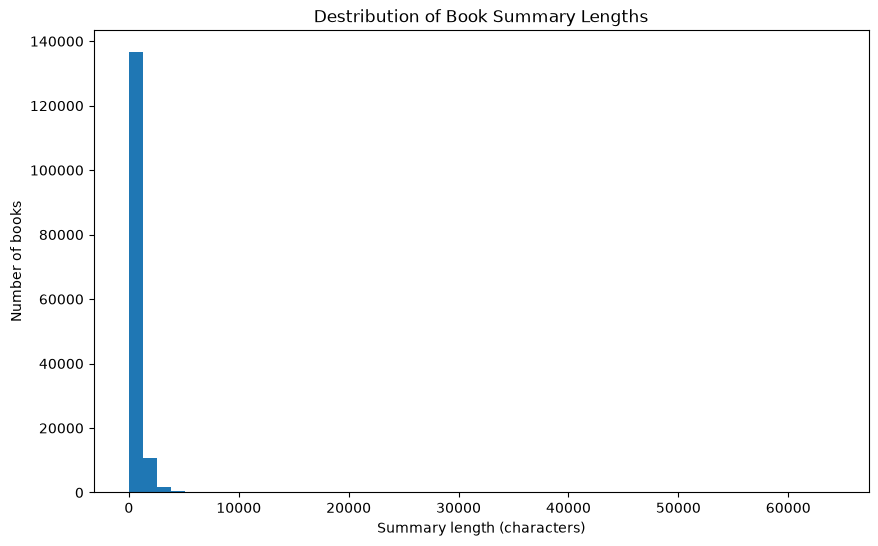

In [103]:
plt.figure(figsize=(10, 6))

plt.hist(books["summary_length"], bins=50)

plt.xlabel("Summary length (characters)")
plt.ylabel("Number of books")
plt.title("Destribution of Book Summary Lengths")

plt.show()

## Cell 51 — Create a saved summary-length figure
This cell saves a report-ready version of the summary-length distribution for later use in the Results/EDA section.

In [ ]:
plt.figure(figsize=(9, 5))

plt.hist(books["summary_length"], bins=50)

plt.xlabel("Summary length (characters)")
plt.ylabel("Number of books")
plt.title("Distribution of Book Summary Lengths")

plt.tight_layout()

plt.savefig(
    "../results/figures/figure3_summary_length.png",
    dpi=300,
    bbox_inches="tight"
)


## Cell 52 — Inspect very short summaries
**Inspect very short summaries**. This cell performs the `inspect very short summaries` step as part of the analysis pipeline. The result is used to verify the data, support a modeling decision, or prepare the next stage of the workflow.

In [ ]:
short_summaries = (
    books[books["summary_length"] > 0]
    .sort_values("summary_length")
    [["book_title", "book_summary", "summary_length"]]
    .head(10)
)

short_summaries

,book_title,book_summary,summary_length
149503,ইতিহাস ২য় পত্র একাদশ,Show More,9
149391,যুক্তিবিদ্যা,Show More,9
149390,যুক্তিবিদ্যা,Show More,9
149387,২০ টি ব‌ইয়ের দাওয়াহ প্যাকেজ,Show More,9
83458,মহানবী ﷺ ও চার খলীফা সিরিজ,Show More,9
83457,State Language Movement in East Bengal 1947,Show More,9
83456,"Policies, Budget and PRSP",Show More,9
83455,Popular Economics,Show More,9
83484,সময়ের সান্দীপনি,Show More,9
83481,কুরআন ও সলাত অনুধাবন (৫০ ভাগ কুরআনের শব্দ) কোর্স,Show More,9


## Cell 53 — Inspect medium-length summaries
**Inspect medium-length summaries**. This cell performs the `inspect medium-length summaries` step as part of the analysis pipeline. The result is used to verify the data, support a modeling decision, or prepare the next stage of the workflow.

In [ ]:
medium_summaries = (
    books[
        (books["summary_length"] >= 100) &
        (books["summary_length"] <= 500)
    ]
    [["book_title", "book_summary", "summary_length"]]
    .sample(10, random_state=42)
)

medium_summaries

,book_title,book_summary,summary_length
19471,এডভান্সড ডস (এডভান্সড ডিস্ক অপারেটিং সিস্টেম),কম্পিউটার চালু করলে র‍্যাম স্মৃতিতে Command.co...,348
52530,মোখলেস ভাই উপাখ্যান,মেসে থাকা সবচেয়ে সিনিয়র ভাই মোখলেস ভাই পরোপকার...,310
136216,আহা আমি,'আহা আমি' জিসান খান শুভ-র প্রথম বই এবং প্রথম ক...,171
114441,Basic Electrical Engineering,Reading books is a kind of enjoyment. Reading ...,283
63937,দ্য রেইপ অব বাংলাদেশ,"""দ্য রেইপ অব বাংলাদেশ"" বইটির সূচিপত্রঃ এক : ধ্...",350
146808,চতুরঙ্গ,রবীন্দ্রনাথের ‘চতুরঙ্গ’ চারটি জীবনদর্শনের—মানব...,368
41110,কোরআনের শিক্ষা,বাজারে কোরআন শিক্ষার অসংখ্য বই রয়েছে কিন্তু কো...,233
128681,Panjeree Communicative English First Paper Spe...,Characteristic: The main features of the book ...,452
138718,এফএম'এস নেসেসারি ভোকাবুলারি,ভোকাবুলারি = পানি হলে কেমন হতো বলুন তো? কি ভাব...,458
76780,নাভীর নিকটে সেমেট্রি,"""নাভীর নিকটে সেমেট্রি"" বইয়ের সংক্ষিপ্ত কথা: প্...",244


## Cell 54 — Improve the existing note: Inspect very long summaries
**Inspect very long summaries**. This cell performs the `inspect very long summaries` step as part of the analysis pipeline. The result is used to verify the data, support a modeling decision, or prepare the next stage of the workflow.

In [ ]:
long_summaries = (
    books[books["summary_length"] > 2000]
    .sort_values("summary_length", ascending=False)
    [["book_title", "book_summary", "summary_length"]]
    .head(5)
)

long_summaries

,book_title,book_summary,summary_length
139794,ইন্টেরিয়র ইনসাইড ভাবনা থেকে বাস্তবতা,"Show More</button> </div> </div> <div class=""t...",64106
40839,ফতোয়ায়ে উসমানী,সূচিপত্র كِتَابُ الزَّكٰوةِ (যাকাত অধ্যায়) ব্য...,32613
40838,ফতোয়ায়ে উসমানী,সূচিপত্র كِتَابُ الزَّكٰوةِ (যাকাত অধ্যায়) ব্য...,32613
79602,ফতোয়ায়ে উসমানী ১,"ফতোয়ায়ে উসমানী ১ম খণ্ড, ফতোয়ায়ে উসমানী ২য় খণ...",29826
79603,ফতোয়ায়ে উসমানী ১,"ফতোয়ায়ে উসমানী ১ম খণ্ড, ফতোয়ায়ে উসমানী ২য় খণ...",29826


## Cell 55 — Plot the report-ready category-frequency figure
This saved version of the category-frequency plot is prepared for later inclusion in the report.

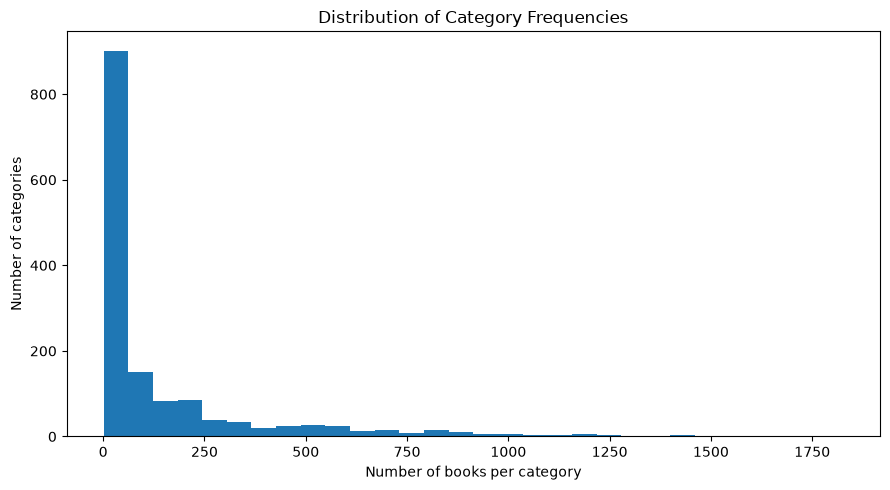

In [13]:
plt.figure(figsize=(9, 5))

plt.hist(category_frequency, bins=30)

plt.xlabel("Number of books per category")
plt.ylabel("Number of categories")
plt.title("Distribution of Category Frequencies")

plt.tight_layout()

plt.savefig(
    "../results/figures/figure1_category_frequency.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Cell 56 — Improve the existing note: Check for exact Show More summaries
The analysis tests whether the literal text `Show More` appears as an entire summary, indicating a scraping artifact rather than book content.

In [ ]:
show_more_count = (
    books["book_summary"]
    .fillna("")
    .str.strip()
    .eq("Show More")
    .sum()
)

print("Exact 'Show More' summaries:", show_more_count)

Exact 'Show More' summaries: 81779


## Cell 57 — Check for HTML tags in summaries
The summary field is checked for embedded HTML markup, another potential scraping artifact.

In [ ]:
html_pattern = r"<[^>]+>"

html_summary_count = (
    books["book_summary"]
    .fillna("")
    .str.contains(html_pattern, regex=True)
    .sum()
)

print("Summaries containing HTML tags:", html_summary_count)

Summaries containing HTML tags: 8


## Cell 58 — Check for Show More anywhere in summaries
This broader check identifies summaries where 'Show More' occurs anywhere in the text, not only as the entire summary.

In [ ]:
show_more_anywhere = (
    books["book_summary"]
    .fillna("")
    .str.contains("Show More", case=False, regex=False)
    .sum()
)

print("Summaries containing 'Show More':", show_more_anywhere)

Summaries containing 'Show More': 149173


## Cell 59 — Clean summaries for comparison
A cleaned summary series is produced while preserving the original raw `book_summary` column.

In [ ]:
clean_summary = (
    books["book_summary"]
    .fillna("")
    .str.replace("Show More", "", regex=False)
    .str.strip()
)

clean_summary_length = clean_summary.str.len()

print(clean_summary_length.describe())

count    149515.000000
mean        415.148915
std         798.211505
min           0.000000
25%           0.000000
50%           0.000000
75%         671.000000
max       64097.000000
Name: book_summary, dtype: float64


## Cell 60 — Measure summary quality after cleaning
Summary lengths are recalculated after removing the scraping artifact to reveal the amount of genuinely usable summary text.

In [ ]:
print(
    "Empty summaries after removing 'Show More':",
    (clean_summary_length == 0).sum()
)

print(
    "Summaries under 50 characters after cleaning:",
    (clean_summary_length < 50).sum()
)

print(
    "Summaries under 100 characters after cleaning:",
    (clean_summary_length < 100).sum()
)

Empty summaries after removing 'Show More': 82119
Summaries under 50 characters after cleaning: 82586
Summaries under 100 characters after cleaning: 83663


## Cell 61 — Inspect title quality
The title field is examined for missingness, duplication, and length before it is used as a model feature.

In [ ]:
print("Empty titles:", (books["book_title"].fillna("").str.strip() == "").sum())

print("Duplicate titles:", books["book_title"].duplicated().sum())

print("\nTitle length statistics:")
print(books["title_length"].describe())

Empty titles: 0
Duplicate titles: 43714

Title length statistics:
count    149515.000000
mean         22.953470
std          13.901194
min           1.000000
25%          14.000000
50%          20.000000
75%          29.000000
max         155.000000
Name: title_length, dtype: float64


## Cell 62 — Improve the existing note: Inspect repeated titles directly
Repeated titles are sampled to distinguish legitimate repeated titles from true duplicate records.

In [ ]:
duplicate_titles = (
    books[books["book_title"].duplicated(keep=False)]
    .sort_values("book_title")
    [["book_id", "book_title", "author_id", "publisher_id", "category_id"]]
)

duplicate_titles.head(20)

,book_id,book_title,author_id,publisher_id,category_id
145188,480118,$100 M অফার,118281,8716.0,725
145189,480118,$100 M অফার,118281,8716.0,725
119194,360288,$100M Offers,118281,14852.0,976
128089,405302,$100M Offers,118281,12579.0,2412
148969,510910,$100M মানি মডেলস,133662,14374.0,2413
147774,505387,$100M মানি মডেলস,118281,14444.0,731
147773,505387,$100M মানি মডেলস,118281,14444.0,731
147318,501419,$100M মানি মডেলস,118281,8716.0,1795
147597,504276,$১০০ মিলিয়ন লিডস,118281,8716.0,1795
147596,504276,$১০০ মিলিয়ন লিডস,118281,8716.0,1795


## Cell 63 — Compare titles across book IDs
The same title is examined across identifiers to determine whether title duplication necessarily means duplicate books.

In [ ]:
title_id_counts = books.groupby("book_title")["book_id"].nunique()

print("Titles appearing with multiple book IDs:",
      (title_id_counts > 1).sum())

print("Titles repeated but linked to only one book ID:",
      (title_id_counts == 1).sum())

Titles appearing with multiple book IDs: 8793
Titles repeated but linked to only one book ID: 97008


## Cell 64 — Check for exact duplicate records
Exact row duplication is quantified separately from title duplication so cleaning decisions do not remove legitimate books.

In [ ]:
duplicate_rows = books.duplicated(keep=False)

print("Exact duplicate rows:", duplicate_rows.sum())

Exact duplicate rows: 37936


## Cell 65 — Count titles that occur more than once
The number of distinct titles occurring multiple times is computed to separate title reuse from exact record duplication.

In [ ]:
title_frequency = books["book_title"].value_counts()

repeated_titles = title_frequency[title_frequency > 1]

print("Number of titles appearing more than once:", len(repeated_titles))
print("Rows belonging to repeated titles:", repeated_titles.sum())

Number of titles appearing more than once: 23725
Rows belonging to repeated titles: 67439


## Cell 66 — Inspect the most repeated titles

In [ ]:
print("Top 20 most repeated book titles:")

repeated_titles.head(20).to_frame()

Top 20 most repeated book titles:


,count
book_title,
Book,340
আল,264
শ্রেষ্ঠ গল্প,174
পথের পাঁচালী,168
চাঁদের পাহাড়,128
উপন্যাস সমগ্র,102
শেষের কবিতা,94
আরণ্যক,94
শ্রেষ্ঠ কবিতা,86


## Cell 67 — Assess duplication after removing exact duplicates
Exact duplicates are removed in a temporary dataframe to see how much title repetition remains when obvious duplicate rows are excluded.

In [ ]:
books_unique_rows = books.drop_duplicates()

unique_row_title_frequency = books_unique_rows["book_title"].value_counts()

repeated_titles_after_exact_duplicates = (
    unique_row_title_frequency[
        unique_row_title_frequency > 1
    ]
)

print("Rows after removing exact duplicates:", len(books_unique_rows))

print(
    "Titles still appearing more than once:",
    len(repeated_titles_after_exact_duplicates)
)

print(
    "Rows belonging to repeated titles:",
    repeated_titles_after_exact_duplicates.sum()
)

Rows after removing exact duplicates: 130540
Titles still appearing more than once: 10954
Rows belonging to repeated titles: 35693


## Cell 68 — Normalize title whitespace
Simple whitespace normalization is tested to see whether formatting differences are creating artificial title uniqueness.

In [ ]:
normalized_titles = (
    books["book_title"]
    .astype(str)
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

normalized_title_frequency = normalized_titles.value_counts()

print(
    "Titles appearing more than once after whitespace normalization:",
    (normalized_title_frequency > 1).sum()
)

print(
    "Rows belonging to repeated normalized titles:",
    normalized_title_frequency[normalized_title_frequency > 1].sum()
)

Titles appearing more than once after whitespace normalization: 23738
Rows belonging to repeated normalized titles: 67486


## Cell 69 — Inspect unusually short titles
Very short titles are inspected rather than automatically removed, because short titles can still be legitimate book titles.

In [ ]:
short_titles = books[
    books["book_title"].str.len() <= 2
]

print("Titles with 2 or fewer characters:", len(short_titles))

short_titles[["book_id", "book_title"]].head(20)

Titles with 2 or fewer characters: 766


,book_id,book_title
95,156,কে
347,861,মৌ
669,1212,ভয়
670,1212,ভয়
716,1237,নি
717,1237,নি
1007,1659,আল
1968,3867,জি
2431,4779,মা
2571,5087,মন


## Cell 70 — Load author and publisher metadata
Author and publisher reference data are loaded to assess whether metadata can contribute useful predictive information in Model 3.

In [4]:
authors = pd.read_json(
    "../data/RokomariBG_Dataset/author.json"
)

publishers = pd.read_json(
    "../data/RokomariBG_Dataset/publisher.json"
)

print("Authors:", authors.shape)
print("Publishers:", publishers.shape)

Authors: (16601, 7)
Publishers: (2757, 5)


## Cell 71 — Inspect author metadata quality
Author fields and missing values are inspected to determine which author attributes are reliable enough for modeling.

In [5]:
print("Author columns:")
print(authors.columns.tolist())

print("\nAuthor dataset info:")
print(authors.info())

print("\nMissing values:")
print(authors.isnull().sum())

Author columns:
['author_id', 'author', 'bio', 'follower_count', 'publisher_name', 'publisher_id', 'known_for_tokens']

Author dataset info:
<class 'pandas.DataFrame'>
RangeIndex: 16601 entries, 0 to 16600
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   author_id         16601 non-null  int64  
 1   author            16576 non-null  str    
 2   bio               3358 non-null   str    
 3   follower_count    3466 non-null   float64
 4   publisher_name    16576 non-null  str    
 5   publisher_id      16576 non-null  float64
 6   known_for_tokens  3358 non-null   object 
dtypes: float64(2), int64(1), object(1), str(3)
memory usage: 908.0+ KB
None

Missing values:
author_id               0
author                 25
bio                 13243
follower_count      13135
publisher_name         25
publisher_id           25
known_for_tokens    13243
dtype: int64


## Cell 72 — Analyze author frequency in the book data

In [6]:
author_book_frequency = (
    books.groupby("author_id")
    .size()
    .sort_values(ascending=False)
)

print("Unique authors appearing in books:",
      author_book_frequency.size)

print("\nBooks per author:")
print(author_book_frequency.describe())

Unique authors appearing in books: 44846

Books per author:
count    44846.000000
mean         3.333965
std         19.182773
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max       2162.000000
dtype: float64


## Cell 73 — Check author rarity thresholds
Author frequency thresholds are examined to identify how many authors have enough repeated observations to be represented efficiently.

In [7]:
print(
    "Authors with exactly 1 book:",
    (author_book_frequency == 1).sum()
)

print(
    "Authors with fewer than 5 books:",
    (author_book_frequency < 5).sum()
)

print(
    "Authors with at least 10 books:",
    (author_book_frequency >= 10).sum()
)

Authors with exactly 1 book: 29516
Authors with fewer than 5 books: 39476
Authors with at least 10 books: 2382


## Cell 74 — Analyze publisher frequency in the book data
Publisher reuse is measured to determine whether publisher IDs provide a practical categorical feature.

In [8]:
publisher_book_frequency = (
    books.groupby("publisher_id")
    .size()
    .sort_values(ascending=False)
)

print("Unique publishers appearing in books:",
      publisher_book_frequency.size)

print("\nBooks per publisher:")
print(publisher_book_frequency.describe())

Unique publishers appearing in books: 6045

Books per publisher:
count    6045.000000
mean       24.677419
std        94.017312
min         1.000000
25%         1.000000
50%         3.000000
75%        12.000000
max      2044.000000
dtype: float64


## Cell 75 — Check publisher rarity thresholds
Publisher frequency thresholds are used to quantify the long tail of rarely occurring publishers.

In [9]:
print(
    "Publishers with exactly 1 book:",
    (publisher_book_frequency == 1).sum()
)

print(
    "Publishers with fewer than 5 books:",
    (publisher_book_frequency < 5).sum()
)

print(
    "Publishers with at least 10 books:",
    (publisher_book_frequency >= 10).sum()
)

Publishers with exactly 1 book: 2064
Publishers with fewer than 5 books: 3603
Publishers with at least 10 books: 1691


## Cell 76 — Load the book-category table for the final modeling check
The book-category relationship table is reloaded so the final modeling population can be reconstructed consistently from the EDA results.

In [10]:
book_categories = pd.read_json(
    "../data/RokomariBG_Dataset/book_to_category.json"
)

print("Book-category relationships:", book_categories.shape)

Book-category relationships: (235475, 2)


## Cell 77 — Reconstruct the frequent-category modeling population
The final modeling population is recreated using the agreed category-frequency threshold so metadata completeness is measured on the same books used in modeling.

In [11]:
category_frequency = (
    book_categories
    .groupby("category_id")["book_id"]
    .nunique()
)

selected_categories = category_frequency[
    category_frequency >= 100
].index.tolist()

labels = (
    book_categories
    .groupby("book_id")["category_id"]
    .apply(list)
    .reset_index()
)

books_unique = (
    books
    .drop_duplicates(subset="book_id", keep="first")
    .copy()
)

modeling_population = books_unique.merge(
    labels,
    on="book_id",
    how="inner"
)

modeling_population["selected_categories"] = (
    modeling_population["category_id_y"]
    .apply(lambda cats: [c for c in cats if c in selected_categories])
)

modeling_population = modeling_population[
    modeling_population["selected_categories"].map(len) > 0
].copy()

print("Modeling population:", len(modeling_population))
print("Selected categories:", len(selected_categories))

Modeling population: 102227
Selected categories: 478


## Cell 78 — Check final author and publisher availability
This final metadata check measures whether author and publisher IDs are present for the exact modeling population used in the experiments.

In [12]:
print("Missing author_id:",
      modeling_population["author_id"].isna().sum())

print("Missing publisher_id:",
      modeling_population["publisher_id"].isna().sum())

print("Books with valid author_id:",
      modeling_population["author_id"].notna().sum())

print("Books with valid publisher_id:",
      modeling_population["publisher_id"].notna().sum())

Missing author_id: 0
Missing publisher_id: 27
Books with valid author_id: 102227
Books with valid publisher_id: 102200
